4.1 LDA TOPIC MODELING

--- Top Words per Topic ---

Topic 0:
science data neural networks learning

Topic 1:
text networks neural topic modeling

Topic 2:
learning modeling topic neural networks


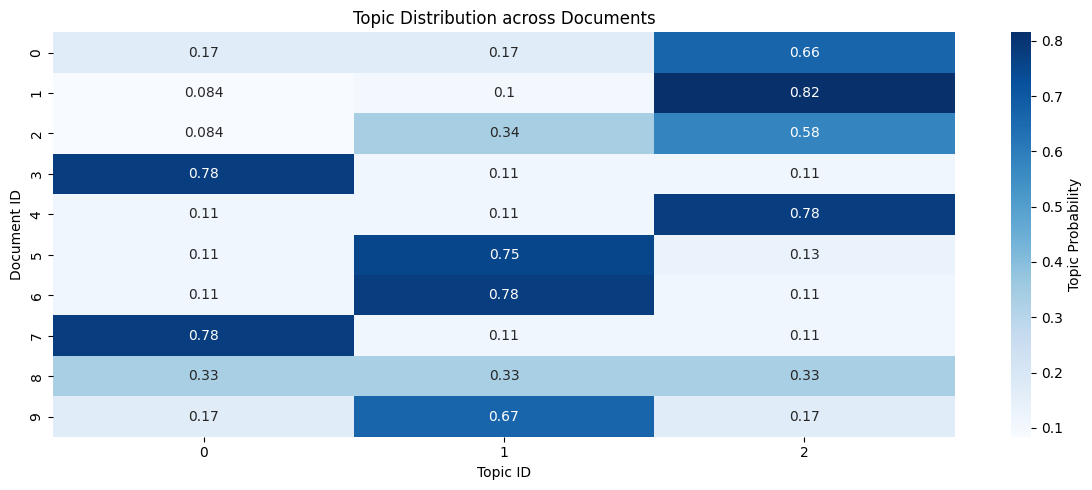

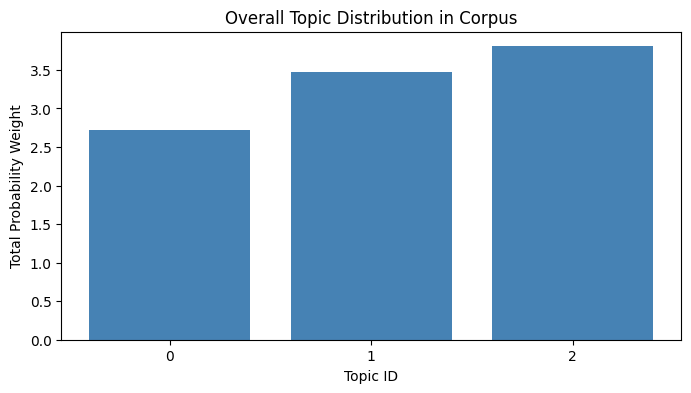


4.2 pyLDAvis INTERACTIVE MAP

Interactive visualization saved as 'lda_visualization.html'


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import pyLDAvis
import pyLDAvis.lda_model

documents = [
    "Machine learning is a field of AI.",
    "Deep learning uses neural networks.",
    "Topic modeling finds hidden structures in text.",
    "Python is great for data science.",
    "LDA is a popular topic modeling technique.",
    "Neural networks require large datasets.",
    "Text mining extracts information from text.",
    "Data science involves statistics and programming.",
    "Artificial intelligence is transforming industries.",
    "Natural language processing helps computers understand text."
]

print("=" * 50)
print("4.1 LDA TOPIC MODELING")
print("=" * 50)

tf_vectorizer = CountVectorizer(stop_words='english', max_df=0.95, min_df=2)
tf = tf_vectorizer.fit_transform(documents)
tf_feature_names = tf_vectorizer.get_feature_names_out()

n_topics = 3
lda_model = LatentDirichletAllocation(n_components=n_topics, random_state=42)
lda_model.fit(tf)

def display_topics(model, feature_names, no_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print(f"\nTopic {topic_idx}:")
        print(" ".join([feature_names[i] for i in topic.argsort()[:-no_top_words - 1:-1]]))

print("\n--- Top Words per Topic ---")
display_topics(lda_model, tf_feature_names, 5)

doc_topic_dist = lda_model.transform(tf)

plt.figure(figsize=(12, 5))
sns.heatmap(doc_topic_dist, annot=True, cmap="Blues", cbar_kws={'label': 'Topic Probability'})
plt.title("Topic Distribution across Documents")
plt.xlabel("Topic ID")
plt.ylabel("Document ID")
plt.tight_layout()
plt.show()

topic_sums = doc_topic_dist.sum(axis=0)
plt.figure(figsize=(8, 4))
plt.bar(range(n_topics), topic_sums, color='steelblue')
plt.title("Overall Topic Distribution in Corpus")
plt.xlabel("Topic ID")
plt.ylabel("Total Probability Weight")
plt.xticks(range(n_topics))
plt.show()

print("\n" + "=" * 50)
print("4.2 pyLDAvis INTERACTIVE MAP")
print("=" * 50)

vis_data = pyLDAvis.lda_model.prepare(lda_model, tf, tf_vectorizer)

pyLDAvis.display(vis_data)

pyLDAvis.save_html(vis_data, 'lda_visualization.html')
print("\nInteractive visualization saved as 'lda_visualization.html'")